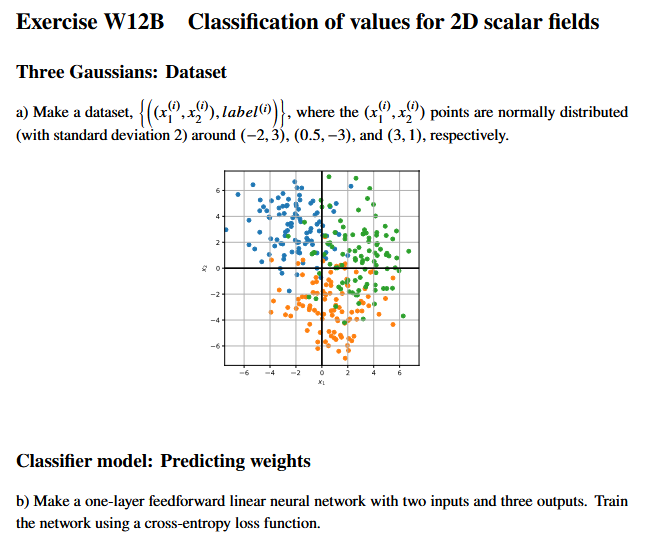
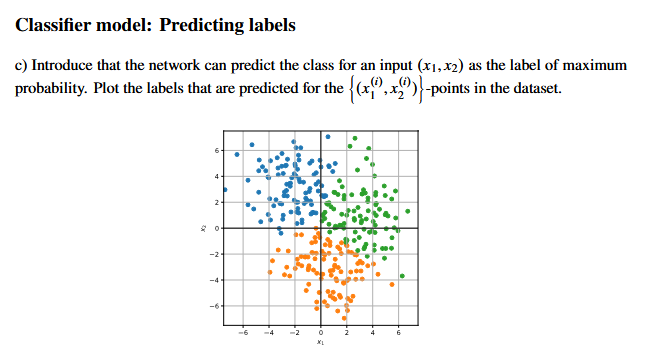

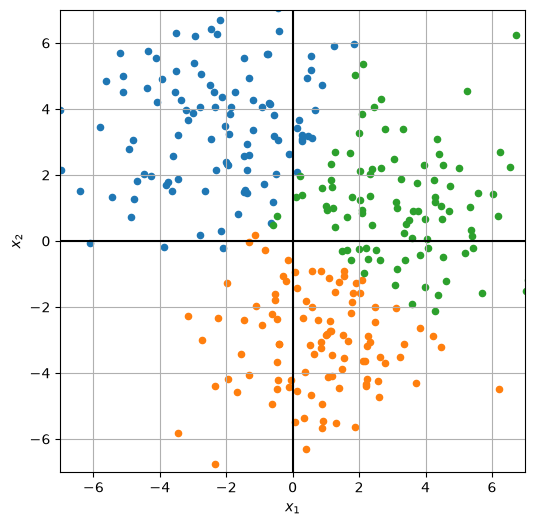

In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np

torch.manual_seed(42)

n_samples = 100
std_dev = 2.0

X0 = torch.randn(n_samples, 2) * std_dev + torch.tensor([-2.0, 3.0])
y0 = torch.zeros(n_samples, dtype=torch.long)

X1 = torch.randn(n_samples, 2) * std_dev + torch.tensor([0.5, -3.0])
y1 = torch.ones(n_samples, dtype=torch.long)

X2 = torch.randn(n_samples, 2) * std_dev + torch.tensor([3.0, 1.0])
y2 = torch.full((n_samples,), 2, dtype=torch.long)

X_train = torch.cat([X0, X1, X2], dim=0)
y_train = torch.cat([y0, y1, y2], dim=0)

class LinearClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Linear(2, 3)

    def forward(self, x):
        return self.network(x)

    def fit(self, X, y, epochs=1000, lr=0.1):
        criterion = nn.CrossEntropyLoss()
        optimizer = optim.SGD(self.parameters(), lr=lr)
        
        self.train()
        for epoch in range(epochs):
            optimizer.zero_grad()
            logits = self(X)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()

    def classify(self, X):
        self.eval()
        with torch.no_grad():
            logits = self(X)
            probabilities = torch.softmax(logits, dim=1)
            predicted_labels = torch.argmax(probabilities, dim=1)
        return probabilities, predicted_labels

model = LinearClassifier()
model.fit(X_train, y_train)

_, predicted_train_labels = model.classify(X_train)

pred_labels_np = predicted_train_labels.numpy()
X_train_np = X_train.numpy()

plt.figure(figsize=(6, 6))

c0 = pred_labels_np == 0
c1 = pred_labels_np == 1
c2 = pred_labels_np == 2

plt.scatter(X_train_np[c0, 0], X_train_np[c0, 1], color='tab:blue', s=20)
plt.scatter(X_train_np[c1, 0], X_train_np[c1, 1], color='tab:orange', s=20)
plt.scatter(X_train_np[c2, 0], X_train_np[c2, 1], color='tab:green', s=20)

plt.axhline(0, color='black', linewidth=1.5)
plt.axvline(0, color='black', linewidth=1.5)
plt.grid(True)
plt.xlabel('$x_1$')
plt.ylabel('$x_2$')
plt.xlim(-7, 7)
plt.ylim(-7, 7)
plt.show()

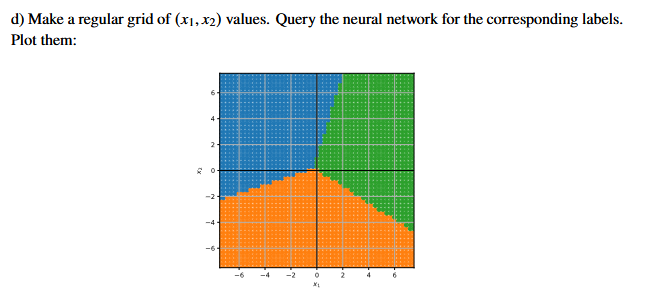

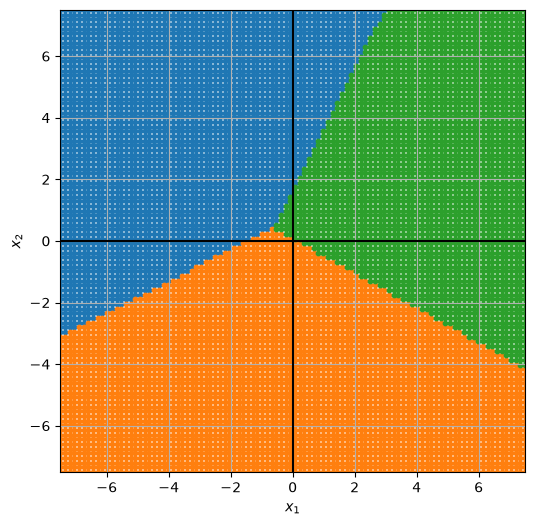

In [5]:
x_range = np.linspace(-7.5, 7.5, 100)
y_range = np.linspace(-7.5, 7.5, 100)
xx_grid, yy_grid = np.meshgrid(x_range, y_range)

grid_inputs = torch.tensor(np.c_[xx_grid.ravel(), yy_grid.ravel()], dtype=torch.float32)
_, grid_preds = model.classify(grid_inputs)

grid_preds_np = grid_preds.numpy()

plt.figure(figsize=(6, 6))

mask0 = grid_preds_np == 0
mask1 = grid_preds_np == 1
mask2 = grid_preds_np == 2

plt.scatter(grid_inputs[mask0, 0].numpy(), grid_inputs[mask0, 1].numpy(), color='tab:blue', s=10)
plt.scatter(grid_inputs[mask1, 0].numpy(), grid_inputs[mask1, 1].numpy(), color='tab:orange', s=10)
plt.scatter(grid_inputs[mask2, 0].numpy(), grid_inputs[mask2, 1].numpy(), color='tab:green', s=10)

plt.axhline(0, color='black', linewidth=1.5)
plt.axvline(0, color='black', linewidth=1.5)
plt.grid(True)
plt.xlabel('$x_1$')
plt.ylabel('$x_2$')
plt.xlim(-7.5, 7.5)
plt.ylim(-7.5, 7.5)
plt.show()

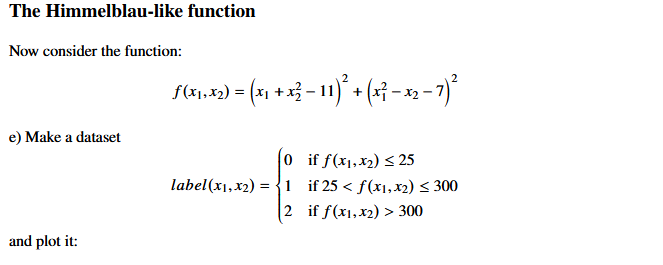

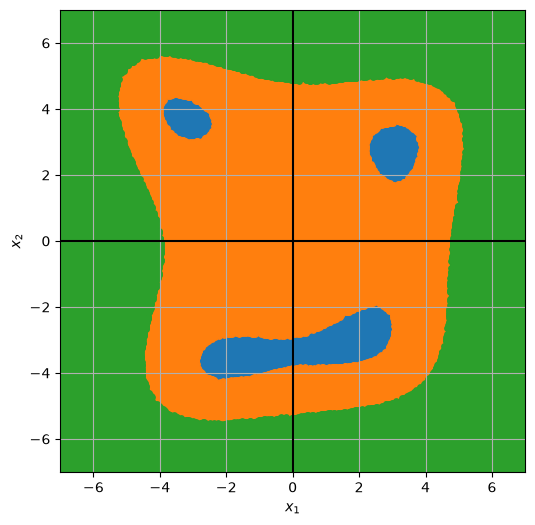

In [20]:
def himmelblau_like(x1, x2):
    return (x1 + x2**2 - 11)**2 + (x1**2 - x2 - 7)**2

n_samples_h = 100_000
X_h = torch.rand(n_samples_h, 2) * 14 - 7

f_vals = himmelblau_like(X_h[:, 0], X_h[:, 1])

y_h = torch.zeros(n_samples_h, dtype=torch.long)
y_h[(f_vals > 25) & (f_vals <= 300)] = 1
y_h[f_vals > 300] = 2

plt.figure(figsize=(6, 6))

mask0 = y_h == 0
mask1 = y_h == 1
mask2 = y_h == 2

plt.scatter(X_h[mask0, 0].numpy(), X_h[mask0, 1].numpy(), color='tab:blue', s=15, label='Label 0 (f ≤ 25)')
plt.scatter(X_h[mask1, 0].numpy(), X_h[mask1, 1].numpy(), color='tab:orange', s=15, label='Label 1 (25 < f ≤ 300)')
plt.scatter(X_h[mask2, 0].numpy(), X_h[mask2, 1].numpy(), color='tab:green', s=15, label='Label 2 (f > 300)')

plt.axhline(0, color='black', linewidth=1.5)
plt.axvline(0, color='black', linewidth=1.5)
plt.grid(True)
plt.xlabel('$x_1$')
plt.ylabel('$x_2$')
plt.xlim(-7, 7)
plt.ylim(-7, 7)
plt.show()

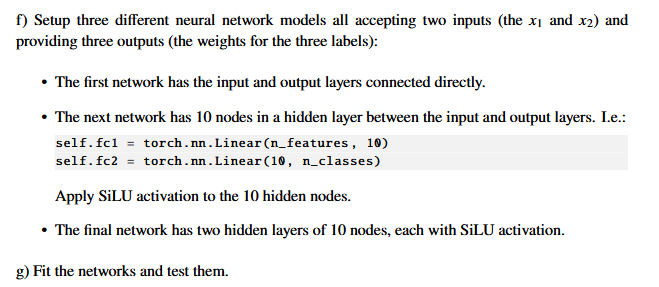

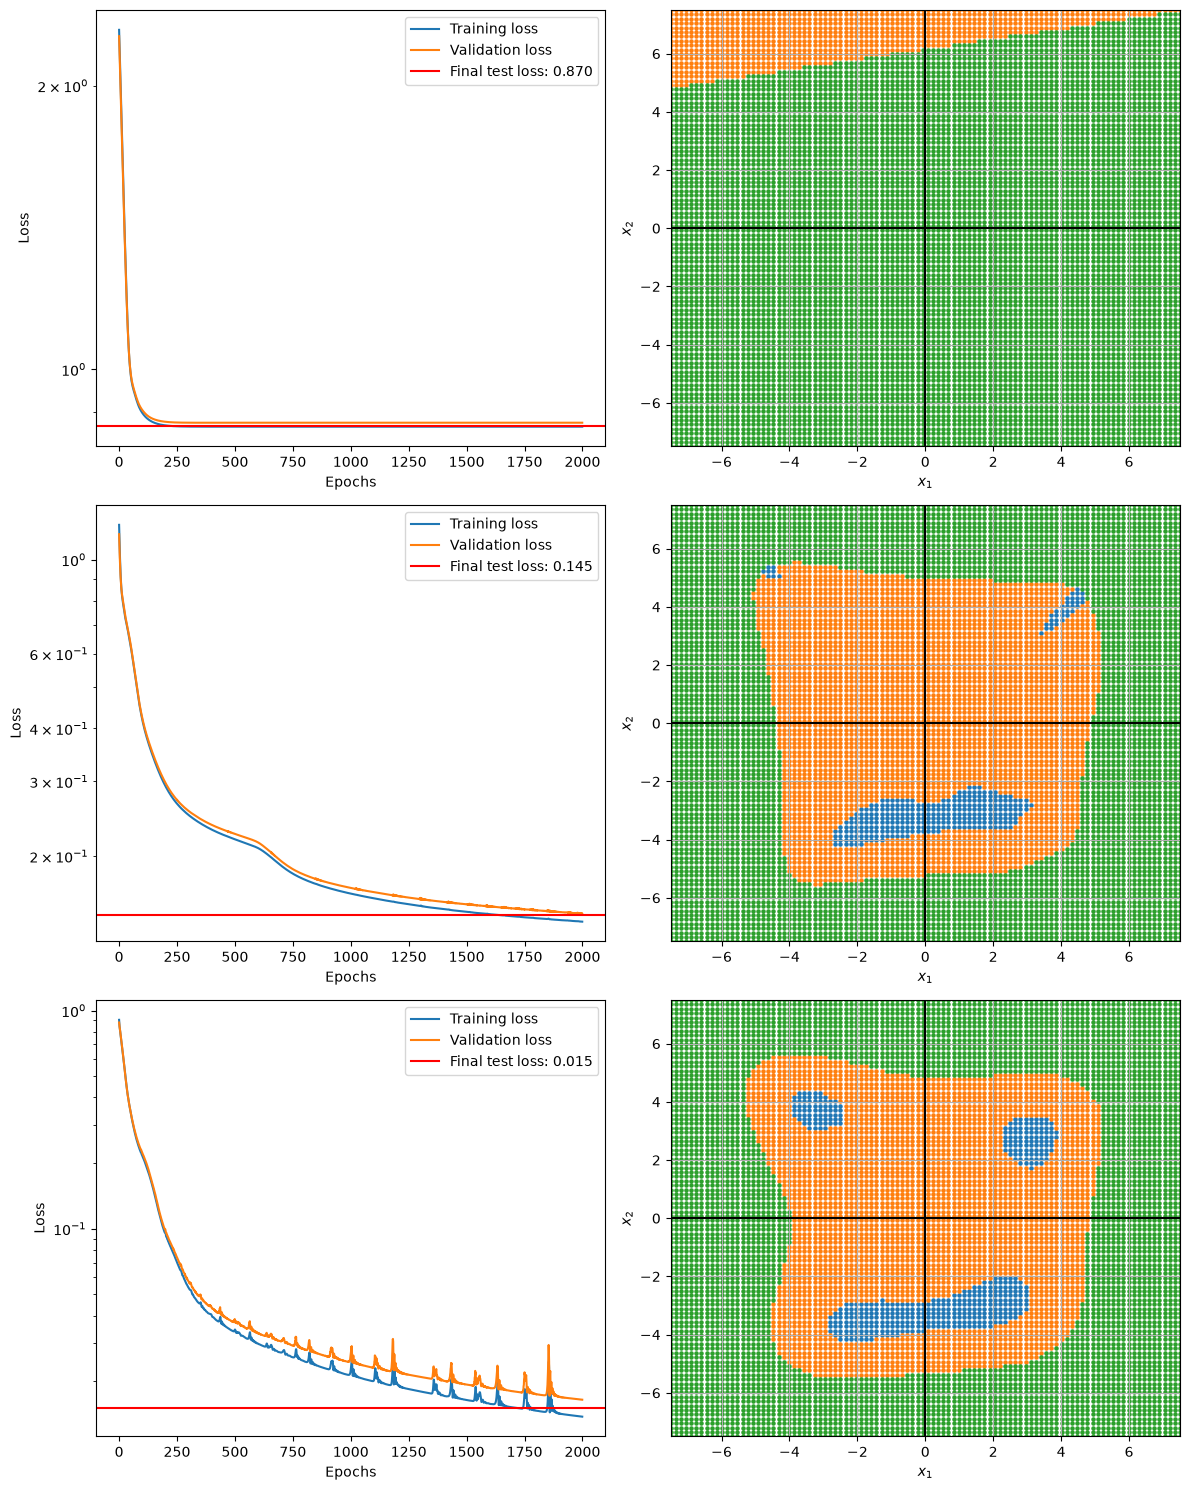

In [21]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

indices = torch.randperm(n_samples_h)
train_size = int(0.8 * n_samples_h)
val_size = int(0.1 * n_samples_h)

train_idx = indices[:train_size]
val_idx = indices[train_size:train_size + val_size]
test_idx = indices[train_size + val_size:]

X_train = X_h[train_idx].to(device)
y_train = y_h[train_idx].to(device)
X_val = X_h[val_idx].to(device)
y_val = y_h[val_idx].to(device)
X_test = X_h[test_idx].to(device)
y_test = y_h[test_idx].to(device)

class BaseClassifier(nn.Module):
    def __init__(self, network):
        super().__init__()
        self.network = network

    def forward(self, x):
        return self.network(x)
        
    def fit(self, X, y, X_v, y_v, epochs=2000, lr=0.01):
        criterion = nn.CrossEntropyLoss()
        optimizer = optim.Adam(self.parameters(), lr=lr)
        
        train_losses = []
        val_losses = []
        
        for epoch in range(epochs):
            self.train()
            optimizer.zero_grad()
            logits = self(X)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()
            train_losses.append(loss.item())
            
            self.eval()
            with torch.no_grad():
                val_logits = self(X_v)
                val_loss = criterion(val_logits, y_v)
                val_losses.append(val_loss.item())
                
        return train_losses, val_losses
            
    def classify(self, X):
        self.eval()
        with torch.no_grad():
            logits = self(X)
            probabilities = torch.softmax(logits, dim=1)
            predicted_labels = torch.argmax(probabilities, dim=1)
        return probabilities, predicted_labels

net1 = nn.Linear(2, 3)

net2 = nn.Sequential(
    nn.Linear(2, 10),
    nn.SiLU(),
    nn.Linear(10, 3)
)

net3 = nn.Sequential(
    nn.Linear(2, 10),
    nn.SiLU(),
    nn.Linear(10, 10),
    nn.SiLU(),
    nn.Linear(10, 3)
)

model1 = BaseClassifier(net1).to(device)
model2 = BaseClassifier(net2).to(device)
model3 = BaseClassifier(net3).to(device)

train_loss1, val_loss1 = model1.fit(X_train, y_train, X_val, y_val)
train_loss2, val_loss2 = model2.fit(X_train, y_train, X_val, y_val)
train_loss3, val_loss3 = model3.fit(X_train, y_train, X_val, y_val)

criterion = nn.CrossEntropyLoss()
model1.eval()
model2.eval()
model3.eval()
with torch.no_grad():
    test_loss1 = criterion(model1(X_test), y_test).item()
    test_loss2 = criterion(model2(X_test), y_test).item()
    test_loss3 = criterion(model3(X_test), y_test).item()

models = [model1, model2, model3]
train_losses = [train_loss1, train_loss2, train_loss3]
val_losses = [val_loss1, val_loss2, val_loss3]
test_losses = [test_loss1, test_loss2, test_loss3]

fig, axes = plt.subplots(3, 2, figsize=(12, 15))

x_range = np.linspace(-7.5, 7.5, 100)
y_range = np.linspace(-7.5, 7.5, 100)
xx_grid, yy_grid = np.meshgrid(x_range, y_range)
grid_inputs = torch.tensor(np.c_[xx_grid.ravel(), yy_grid.ravel()], dtype=torch.float32).to(device)

for i in range(3):
    ax_loss = axes[i, 0]
    ax_loss.semilogy(train_losses[i], label='Training loss')
    ax_loss.semilogy(val_losses[i], label='Validation loss')
    ax_loss.axhline(test_losses[i], color='red', label=f'Final test loss: {test_losses[i]:.3f}')
    ax_loss.set_xlabel('Epochs')
    ax_loss.set_ylabel('Loss')
    ax_loss.legend()
    
    _, grid_preds = models[i].classify(grid_inputs)
    grid_preds_np = grid_preds.cpu().numpy()
    grid_inputs_np = grid_inputs.cpu().numpy()
    
    ax_bound = axes[i, 1]
    mask0 = grid_preds_np == 0
    mask1 = grid_preds_np == 1
    mask2 = grid_preds_np == 2
    
    ax_bound.scatter(grid_inputs_np[mask0, 0], grid_inputs_np[mask0, 1], color='tab:blue', s=5)
    ax_bound.scatter(grid_inputs_np[mask1, 0], grid_inputs_np[mask1, 1], color='tab:orange', s=5)
    ax_bound.scatter(grid_inputs_np[mask2, 0], grid_inputs_np[mask2, 1], color='tab:green', s=5)
    
    ax_bound.axhline(0, color='black', linewidth=1.5)
    ax_bound.axvline(0, color='black', linewidth=1.5)
    ax_bound.grid(True)
    ax_bound.set_xlabel('$x_1$')
    ax_bound.set_ylabel('$x_2$')
    ax_bound.set_xlim(-7.5, 7.5)
    ax_bound.set_ylim(-7.5, 7.5)

plt.tight_layout()
plt.show()